In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import missingno as msno
import xgboost as xgb
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import shap

In [3]:
results_df = pd.read_excel("../../data/processed/results_data_third5.xlsx")
results_df

,Model,MAE,RMSE,R²
0,Linear Regression,9.107352,11.230568,0.150284
1,Decision Tree,6.473843,9.167781,0.433762
2,Random Forest,5.211084,7.137036,0.656833
3,Bagging,5.230529,7.154104,0.655189
4,SVR,9.816996,12.189037,-0.000943
5,XGBoost,5.769817,7.589160,0.611977
6,Voting,5.765335,7.613639,0.609469


In [4]:
df = pd.read_excel("../../data/processed/Third_5_year_mine_data_cleaned.xlsx")
df.columns = df.columns.str.strip()
df.head()

,YEAR,SEASON,MONTH,LOCATION,WEEK,Temperature,Relative_humidity,RF-CUMULATIVE,Wind_speed,Wind_direction,Road_width,Distance,Production,Vehicle Capacity_1,Vehicle Capacity_2,PM10,PM2.5
0,2023,WINTER,DECEMBER,HAUL ROAD,1,30.1,64.5,1.0,2.55,East,12.5,24.3,157650,25000,35000,56.8,42.6
1,2023,WINTER,DECEMBER,HAUL ROAD,1,29.2,70.3,1.0,2.55,East,12.5,24.3,157650,25000,35000,62.4,41.9
2,2023,WINTER,DECEMBER,HAUL ROAD,2,27.6,68.0,0.0,2.55,East,12.5,24.3,157650,25000,35000,63.9,43.6
3,2023,WINTER,DECEMBER,HAUL ROAD,2,24.5,85.3,0.0,2.55,East,12.5,24.3,157650,25000,35000,65.7,41.9
4,2023,WINTER,DECEMBER,HAUL ROAD,3,28.8,58.9,0.0,2.55,East,12.5,24.3,157650,25000,35000,60.2,39.5


In [5]:
df = pd.get_dummies(df, columns=['Wind_direction'])

In [6]:
df.columns

Index(['YEAR', 'SEASON', 'MONTH', 'LOCATION', 'WEEK', 'Temperature',
       'Relative_humidity', 'RF-CUMULATIVE', 'Wind_speed', 'Road_width',
       'Distance', 'Production', 'Vehicle Capacity_1', 'Vehicle Capacity_2',
       'PM10', 'PM2.5', 'Wind_direction_East', 'Wind_direction_East-West',
       'Wind_direction_Northeast', 'Wind_direction_South East',
       'Wind_direction_South West', 'Wind_direction_West',
       'Wind_direction_West-East'],
      dtype='object')

In [10]:
features = [
        "Temperature",
        "Relative_humidity",
        "RF-CUMULATIVE",
        "Wind_speed",
        'Wind_direction_East',
        'Wind_direction_East-West',
        'Wind_direction_Northeast',
        'Wind_direction_South East',
        'Wind_direction_South West',
        'Wind_direction_West',
        'Wind_direction_West-East',
        "Road_width",
        "Distance",
        "Production",
        "Vehicle Capacity_1",
        "Vehicle Capacity_2",
]

target_pm10 = "PM10"
target_pm25 = "PM2.5"

In [11]:
X = df[features]
y = df[target_pm10]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

C:\Users\DELL\AppData\Local\Temp\ipykernel_23600\3588624545.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


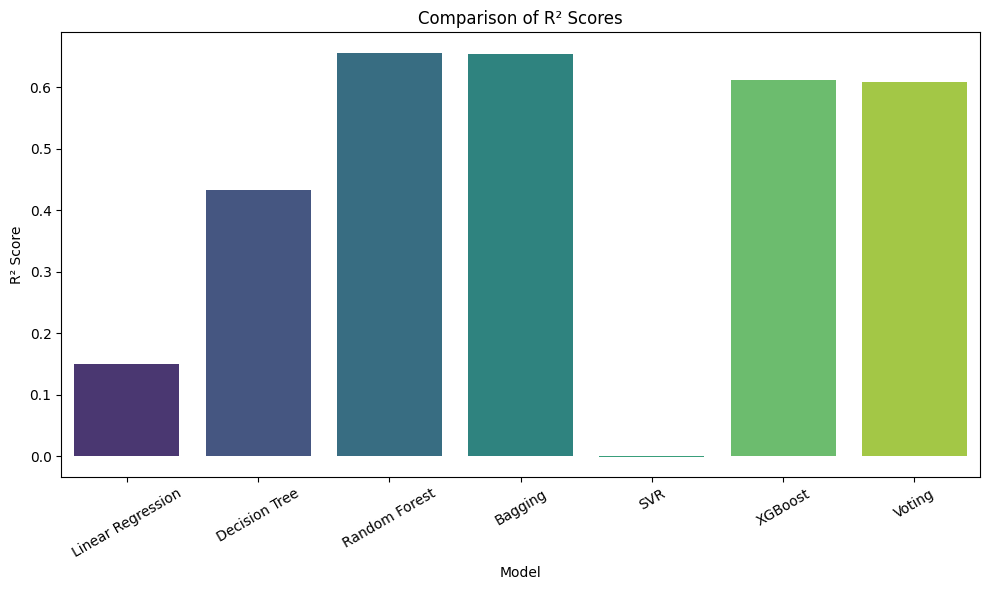

In [12]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R²",
    palette="viridis"
)

plt.title("Comparison of R² Scores")

plt.xticks(rotation=30)

plt.ylabel("R² Score")

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_23600\1072115408.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


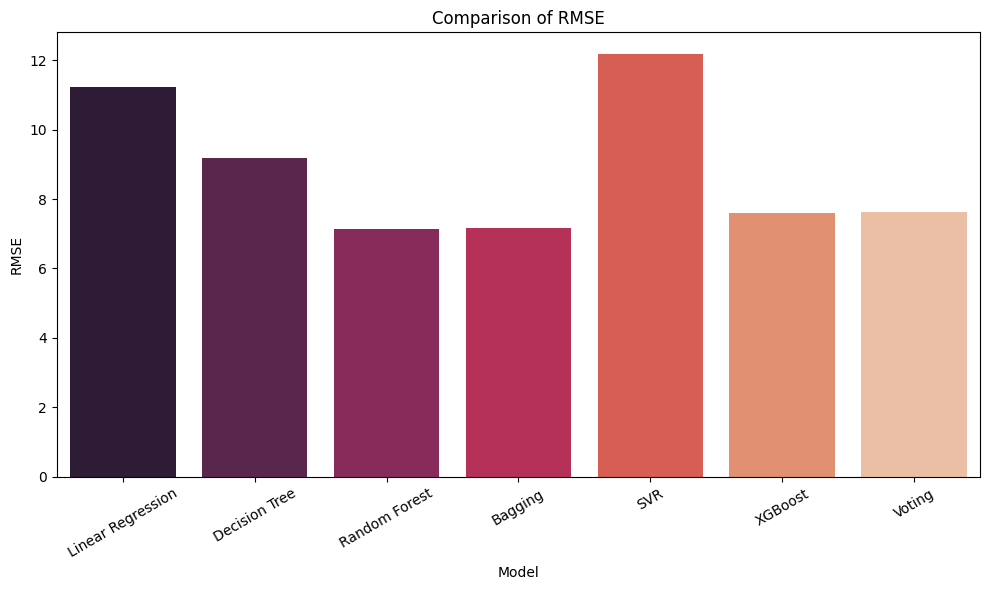

In [13]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    palette="rocket"
)

plt.title("Comparison of RMSE")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_23600\1874031892.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


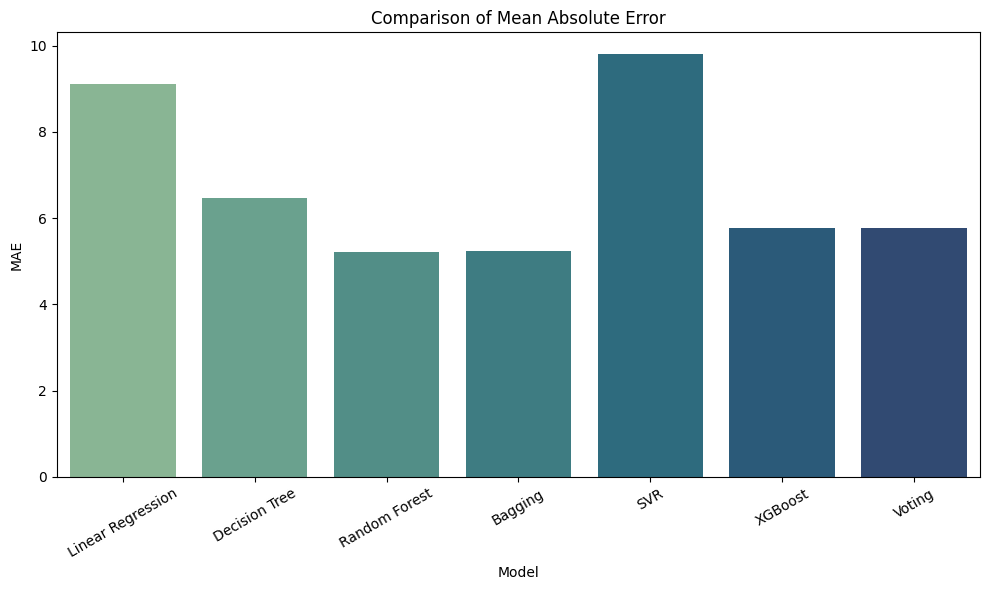

In [14]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    palette="crest"
)

plt.title("Comparison of Mean Absolute Error")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_23600\1874031892.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


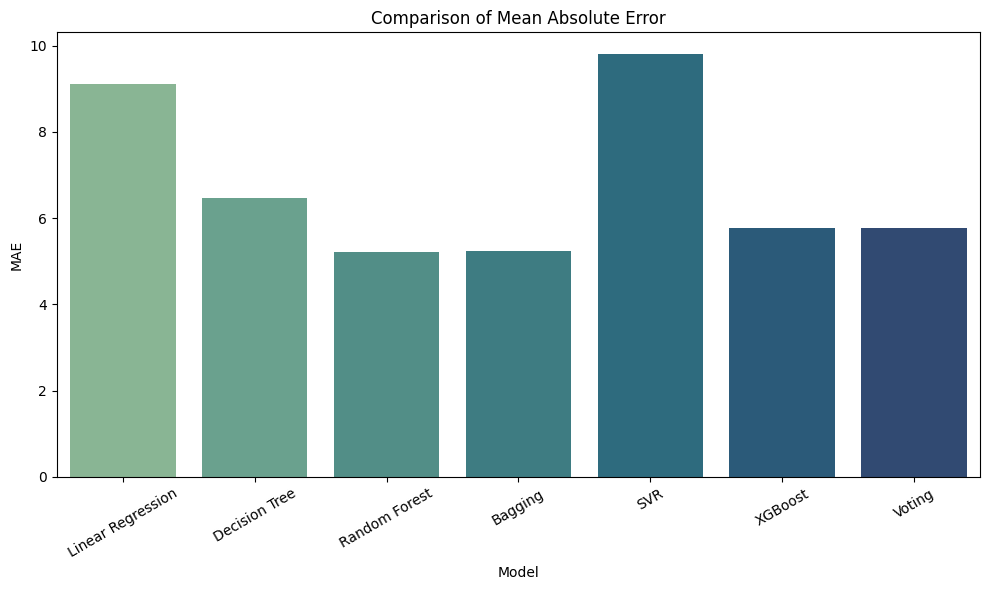

In [15]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    palette="crest"
)

plt.title("Comparison of Mean Absolute Error")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

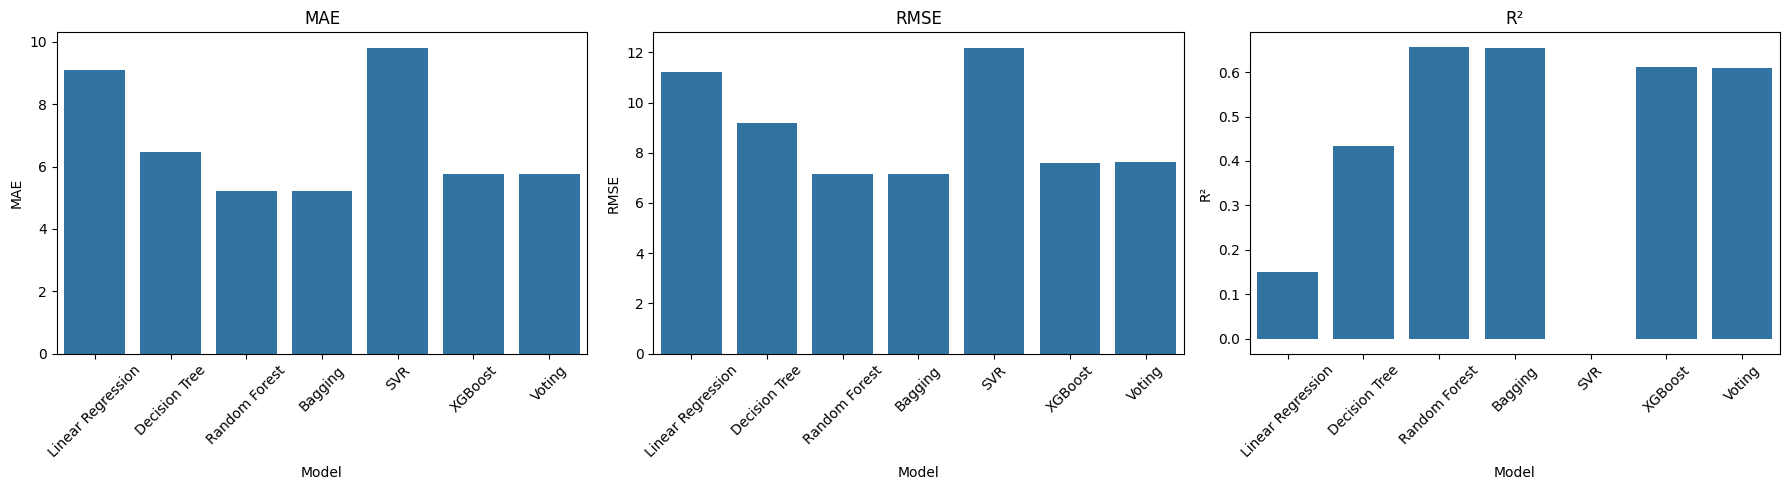

In [16]:
fig, axes = plt.subplots(1,3, figsize=(18,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    ax=axes[0]
)

axes[0].set_title("MAE")

axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    ax=axes[1]
)

axes[1].set_title("RMSE")

axes[1].tick_params(axis='x', rotation=45)

sns.barplot(
    data=results_df,
    x="Model",
    y="R²",
    ax=axes[2]
)

axes[2].set_title("R²")

axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()

plt.show()

In [17]:
# XGBoost
xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

In [18]:
mae = mean_absolute_error(y_test, xgb_pred)
rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
r2 = r2_score(y_test, xgb_pred)

print(mae)
print(rmse)
print(r2)

5.769816793484343
7.589159750645912
0.6119767281075374


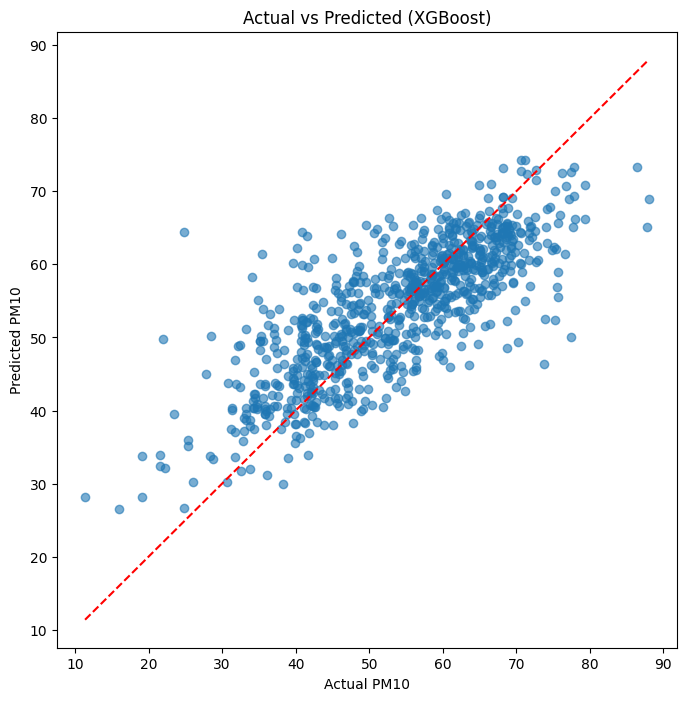

In [19]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    xgb_pred,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual PM10")

plt.ylabel("Predicted PM10")

plt.title("Actual vs Predicted (XGBoost)")

plt.show()

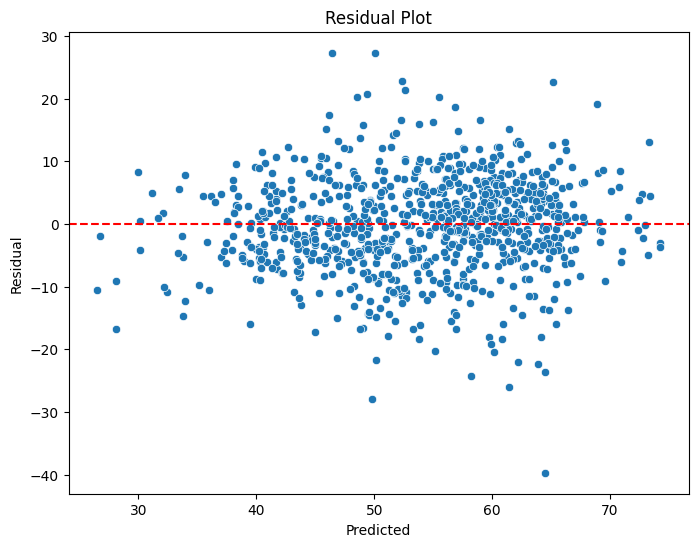

In [20]:
residuals = y_test - xgb_pred

plt.figure(figsize=(8,6))

sns.scatterplot(
    x=xgb_pred,
    y=residuals
)

plt.axhline(
    0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted")

plt.ylabel("Residual")

plt.title("Residual Plot")

plt.show()

In [21]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

,Feature,Importance
6,Wind_direction_Northeast,0.237558
10,Wind_direction_West-East,0.140299
9,Wind_direction_West,0.119957
8,Wind_direction_South West,0.112613
13,Production,0.084925
2,RF-CUMULATIVE,0.077650
5,Wind_direction_East-West,0.051888
3,Wind_speed,0.044272
1,Relative_humidity,0.034014
0,Temperature,0.030779


C:\Users\DELL\AppData\Local\Temp\ipykernel_23600\3158664850.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


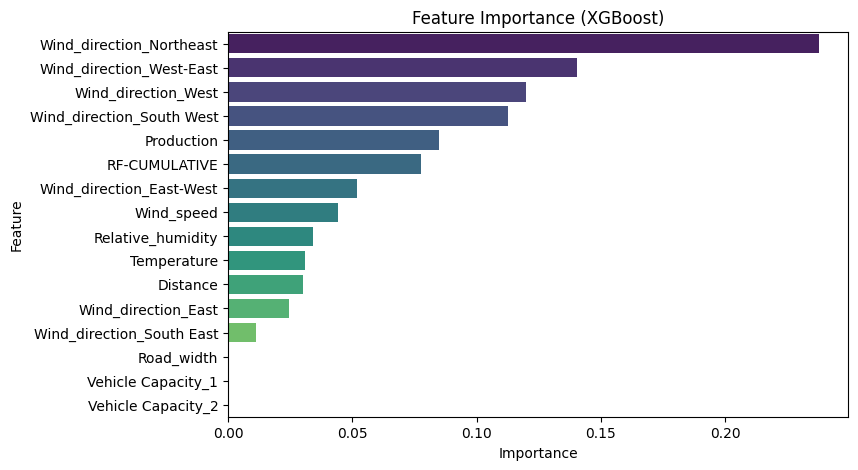

In [22]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Feature Importance (XGBoost)")

plt.show()

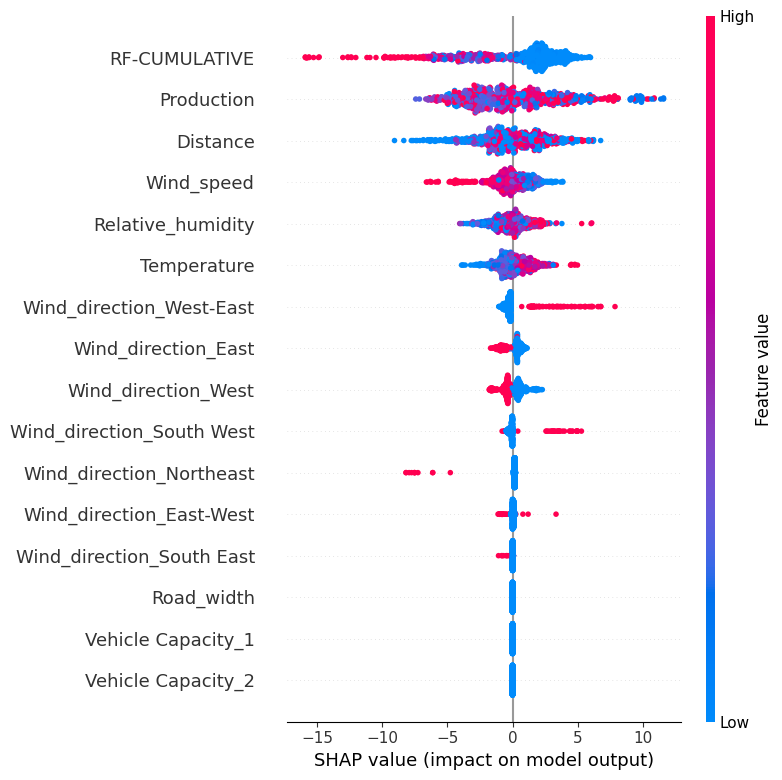

In [23]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)